In [1]:
import os
import shutil
import random
from pathlib import Path
from collections import Counter
from tqdm import tqdm

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, WeightedRandomSampler
from torchvision import datasets, transforms

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
from PIL import Image


# Config
BASE = Path("Dataset")
OUT = Path("Dataset_filtered")
TOP_K = 8
SEED = 42
BATCH_SIZE = 32
NUM_WORKERS = 4
NUM_EPOCHS = 20
LR = 1e-3
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)


#Selecting top_k classes
all_class_dirs = [d for d in BASE.iterdir() if d.is_dir() and d.name not in ["train","val","test"]]
counts = {d.name: len(list(d.glob("*"))) for d in all_class_dirs}
sorted_by_count = sorted(counts.items(), key=lambda x: x[1], reverse=True)
print("Found classes and counts (top 20):")
for name, c in sorted_by_count[:20]:
    print(f"  {name:40s} : {c}")

top_classes = [name for name, c in sorted_by_count[:TOP_K]]
print(f"\nKeeping top {TOP_K} classes:\n", top_classes)


# filtered dataset structure, splited 70/15/15
for split in ["train","val","test"]:
    (OUT / split).mkdir(parents=True, exist_ok=True)

for cls in top_classes:
    src = BASE / cls
    images = list(src.glob("*"))
    if len(images) == 0:
        continue
    random.shuffle(images)
    n = len(images)
    n_train = int(0.7 * n)
    n_val = int(0.15 * n)
    # create dest folders
    (OUT / "train" / cls).mkdir(parents=True, exist_ok=True)
    (OUT / "val" / cls).mkdir(parents=True, exist_ok=True)
    (OUT / "test" / cls).mkdir(parents=True, exist_ok=True)
    # copy
    for p in images[:n_train]:
        shutil.copy(p, OUT / "train" / cls / p.name)
    for p in images[n_train:n_train+n_val]:
        shutil.copy(p, OUT / "val" / cls / p.name)
    for p in images[n_train+n_val:]:
        shutil.copy(p, OUT / "test" / cls / p.name)

print("Filtered dataset created at", OUT)

Device: cuda
Found classes and counts (top 20):
  Tomato__Tomato_YellowLeaf__Curl_Virus    : 3209
  Tomato_Bacterial_spot                    : 2127
  Apple___Apple_scab                       : 2016
  Apple___healthy                          : 2008
  Apple___Black_rot                        : 1987
  Tomato_Late_blight                       : 1909
  Corn_(maize)___Northern_Leaf_Blight      : 1908
  Corn_(maize)___Common_rust_              : 1907
  Corn_(maize)___healthy                   : 1859
  Tomato_Septoria_leaf_spot                : 1771
  Apple___Cedar_apple_rust                 : 1760
  Tomato_Spider_mites_Two_spotted_spider_mite : 1676
  Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot : 1642
  Tomato_healthy                           : 1591
  Pepper__bell___healthy                   : 1478
  Tomato__Target_Spot                      : 1404
  Potato___Early_blight                    : 1000
  Potato___Late_blight                     : 1000
  Tomato_Early_blight                  

In [2]:
# Transforms, Datasets, DataLoaders
train_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomRotation(25),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.05),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

val_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

train_dataset = datasets.ImageFolder(OUT / "train", transform=train_transform)
val_dataset = datasets.ImageFolder(OUT / "val", transform=val_transform)
test_dataset = datasets.ImageFolder(OUT / "test", transform=val_transform)

classes = train_dataset.classes
num_classes = len(classes)
print("Classes used:", classes)
print("Num classes:", num_classes)

# Weighted sampler (на случай, если внутри топ-к все равно есть дисбаланс)
class_weights = compute_class_weight(class_weight='balanced',
                                     classes=np.arange(num_classes),
                                     y=train_dataset.targets)
class_weights = torch.tensor(class_weights, dtype=torch.float).to(DEVICE)
sample_weights = [class_weights[t] for t in train_dataset.targets]
sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, sampler=sampler,
                          num_workers=NUM_WORKERS, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=True)

Classes used: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___healthy', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Tomato_Bacterial_spot', 'Tomato_Late_blight', 'Tomato__Tomato_YellowLeaf__Curl_Virus']
Num classes: 8


In [3]:
#Model (CustomCNN with BatchNorm)
import torch.nn.functional as F

class CustomCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.conv1 = nn.Conv2d(3,32,3,padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32,64,3,padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.conv3 = nn.Conv2d(64,128,3,padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.pool = nn.MaxPool2d(2,2)
        self.dropout = nn.Dropout(0.5)

        with torch.no_grad():
            dummy = torch.zeros(1,3,224,224)
            x = self.pool(F.relu(self.bn1(self.conv1(dummy))))
            x = self.pool(F.relu(self.bn2(self.conv2(x))))
            x = self.pool(F.relu(self.bn3(self.conv3(x))))
            flatten_dim = x.numel()

        self.fc1 = nn.Linear(flatten_dim, 256)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self,x):
        x = F.relu(self.bn1(self.conv1(x))); x = self.pool(x)
        x = F.relu(self.bn2(self.conv2(x))); x = self.pool(x)
        x = F.relu(self.bn3(self.conv3(x))); x = self.pool(x)
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x


model = CustomCNN(num_classes).to(DEVICE)
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.Adam(model.parameters(), lr=LR)


In [4]:
#Training loop (mixed precision)
from torch.cuda.amp import autocast, GradScaler
scaler = GradScaler()

best_val_acc = 0.0
train_losses, val_losses, train_accs, val_accs = [], [], [], []

for epoch in range(NUM_EPOCHS):
    model.train()
    running_loss, running_corrects = 0.0, 0
    for images, labels in tqdm(train_loader, desc=f"Train epoch {epoch+1}/{NUM_EPOCHS}"):
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        with autocast():
            outputs = model(images)
            loss = criterion(outputs, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        running_loss += loss.item() * images.size(0)
        preds = torch.argmax(outputs, 1)
        running_corrects += torch.sum(preds == labels).item()

    epoch_loss = running_loss / len(train_dataset)
    epoch_acc = running_corrects / len(train_dataset)
    train_losses.append(epoch_loss); train_accs.append(epoch_acc)

    # validation
    model.eval()
    val_loss_total, val_corrects = 0.0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_loss_total += loss.item() * images.size(0)
            preds = torch.argmax(outputs, 1)
            val_corrects += torch.sum(preds == labels).item()
    val_loss = val_loss_total / len(val_dataset)
    val_acc = val_corrects / len(val_dataset)
    val_losses.append(val_loss); val_accs.append(val_acc)

    print(f"Epoch {epoch+1}/{NUM_EPOCHS}  Train Loss={epoch_loss:.4f} Acc={epoch_acc:.4f}  Val Loss={val_loss:.4f} Acc={val_acc:.4f}")

    # save best
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "best_model_filtered.pth")
        print("[INFO] Saved best_model_filtered.pth")


C:\Users\Tensa\AppData\Local\Temp\ipykernel_4728\172126783.py:3: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
Train epoch 1/20:   0%|          | 0/374 [00:00<?, ?it/s]C:\Users\Tensa\AppData\Local\Temp\ipykernel_4728\172126783.py:14: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Train epoch 1/20: 100%|██████████| 374/374 [00:54<00:00,  6.89it/s]


Epoch 1/20  Train Loss=3.4123 Acc=0.3773  Val Loss=0.9849 Acc=0.6831
[INFO] Saved best_model_filtered.pth


Train epoch 2/20: 100%|██████████| 374/374 [00:45<00:00,  8.24it/s]


Epoch 2/20  Train Loss=1.3104 Acc=0.4920  Val Loss=0.8281 Acc=0.6596


Train epoch 3/20: 100%|██████████| 374/374 [00:50<00:00,  7.39it/s]


...

Epoch 18/20  Train Loss=0.7782 Acc=0.7050  Val Loss=0.2618 Acc=0.9500
[INFO] Saved best_model_filtered.pth


Train epoch 19/20: 100%|██████████| 374/374 [00:35<00:00, 10.50it/s]


Epoch 19/20  Train Loss=0.7420 Acc=0.7183  Val Loss=0.2094 Acc=0.9469


Train epoch 20/20: 100%|██████████| 374/374 [00:35<00:00, 10.47it/s]


Epoch 20/20  Train Loss=0.7114 Acc=0.7245  Val Loss=0.2339 Acc=0.9254


C:\Users\Tensa\AppData\Local\Temp\ipykernel_4728\1575382890.py:8: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('best_model_filtered.pth', m

                                       precision    recall  f1-score   support

                   Apple___Apple_scab       0.90      0.94      0.92       303
                    Apple___Black_rot       0.97      0.92      0.94       299
                      Apple___healthy       0.94      0.98      0.96       302
          Corn_(maize)___Common_rust_       1.00      0.97      0.98       287
  Corn_(maize)___Northern_Leaf_Blight       0.99      1.00      0.99       287
                Tomato_Bacterial_spot       0.90      0.92      0.91       320
                   Tomato_Late_blight       0.95      0.93      0.94       287
Tomato__Tomato_YellowLeaf__Curl_Virus       0.96      0.95      0.96       482

                             accuracy                           0.95      2567
                            macro avg       0.95      0.95      0.95      2567
                         weighted avg       0.95      0.95      0.95      2567



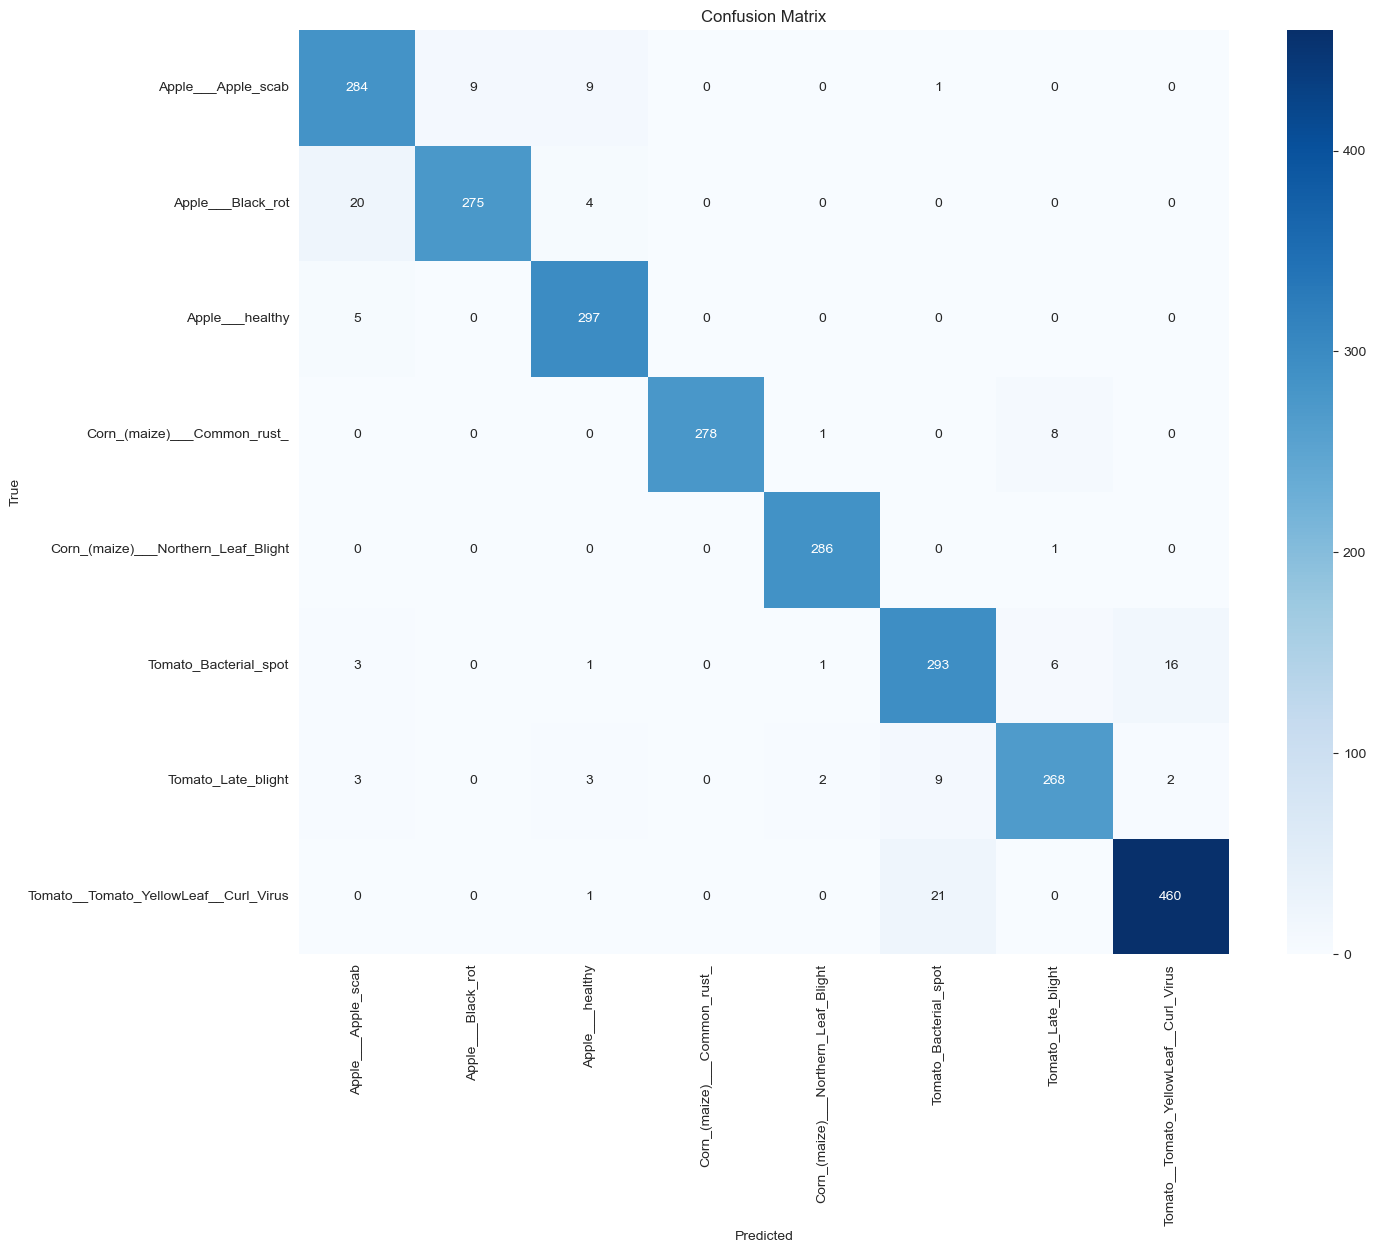

In [7]:
import torch
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model.load_state_dict(torch.load('best_model_filtered.pth', map_location=device))
model = model.to(device)
model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        preds = torch.argmax(outputs, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print(classification_report(all_labels, all_preds, target_names=classes))

# Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(15, 12))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=classes,
    yticklabels=classes,
    cmap='Blues'
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()


In [8]:
from PIL import Image

def predict_image(image_path, model, transform, classes):
    model.eval()
    image = Image.open(image_path).convert('RGB')
    image = transform(image).unsqueeze(0).to(device)
    with torch.no_grad():
        output = model(image)
        pred = torch.argmax(output, 1).item()
    return classes[pred]

# Example usage
sample_image = 'Dataset/Corn_(maize)___Common_rust_/RS_Rust 1646.JPG'
prediction = predict_image(sample_image, model, val_transform, classes)
print(f"Predicted class: {prediction}")


Predicted class: Corn_(maize)___Common_rust_


In [9]:
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
from torchvision import transforms

# Трансформация без аугментаций
clean_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

# Путь к train-папке (та, где лежат только top-K классы)
train_dir = "Dataset_filtered/train"

# Создаем датасет
train_dataset_clean = ImageFolder(root=train_dir, transform=clean_transform)


print("Classes in dataset:", train_dataset_clean.classes)


Classes in dataset: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___healthy', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Tomato_Bacterial_spot', 'Tomato_Late_blight', 'Tomato__Tomato_YellowLeaf__Curl_Virus']


In [10]:
from collections import defaultdict
model.eval()
per_class = defaultdict(lambda: [0,0])  # [correct, total]
with torch.no_grad():
    for imgs, labels in DataLoader(train_dataset_clean, batch_size=64):
        imgs, labels = imgs.to(device), labels.to(device)
        preds = model(imgs).argmax(1)
        for p, t in zip(preds.cpu().numpy(), labels.cpu().numpy()):
            per_class[t][1] += 1
            if p == t: per_class[t][0] += 1

for idx, (corr, tot) in per_class.items():
    print(idx, classes[idx], corr / tot)


0 Apple___Apple_scab 0.9390503189227498
1 Apple___Black_rot 0.9474820143884892
2 Apple___healthy 0.9622775800711744
3 Corn_(maize)___Common_rust_ 0.9842578710644677
4 Corn_(maize)___Northern_Leaf_Blight 0.9977528089887641
5 Tomato_Bacterial_spot 0.8991935483870968
6 Tomato_Late_blight 0.9318862275449101
7 Tomato__Tomato_YellowLeaf__Curl_Virus 0.9523385300668151


F1-scores per class: [0.91909385 0.94339623 0.96272285 0.9840708  0.99133449 0.90993789
 0.94035088 0.95833333]
Precision per class: [0.9015873  0.96830986 0.94285714 1.         0.9862069  0.90432099
 0.94699647 0.9623431 ]
Recall per class: [0.93729373 0.91973244 0.98344371 0.96864111 0.99651568 0.915625
 0.93379791 0.95435685]


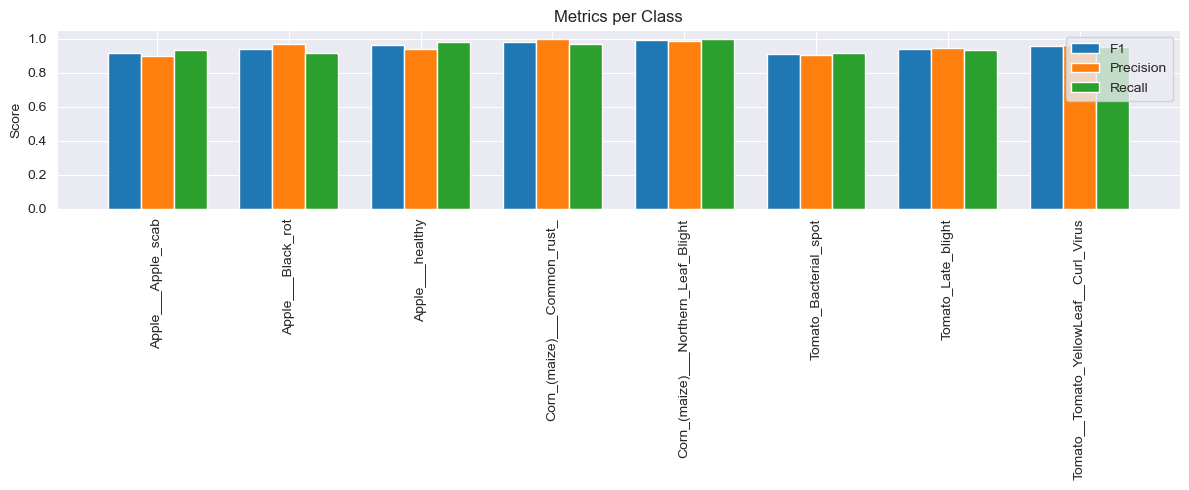

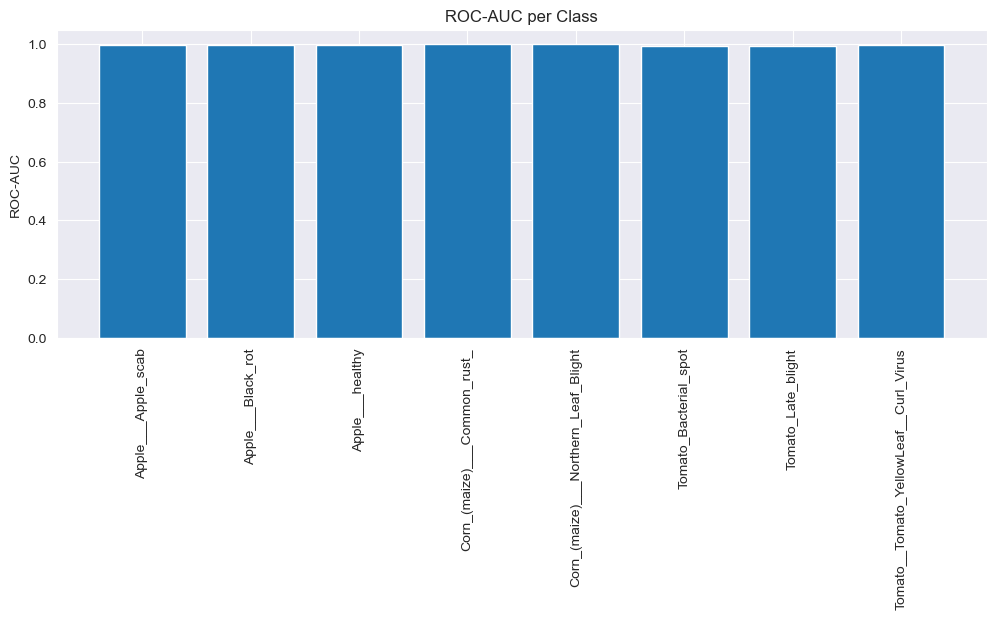

In [11]:
# -----------------------------
# METRICS VISUALIZATION
# -----------------------------
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score
from sklearn.preprocessing import label_binarize
import numpy as np
import torch

# collect all predictions and true labels from test set
all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        outputs = model(imgs)
        probs = torch.softmax(outputs, dim=1)
        preds = torch.argmax(probs, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

# compute metrics per class
f1_scores = f1_score(all_labels, all_preds, average=None)
precisions = precision_score(all_labels, all_preds, average=None)
recalls = recall_score(all_labels, all_preds, average=None)

# print metrics
print("F1-scores per class:", f1_scores)
print("Precision per class:", precisions)
print("Recall per class:", recalls)

# plot F1, Precision, Recall per class
plt.figure(figsize=(12,5))
x = np.arange(len(classes))
width = 0.25

plt.bar(x - width, f1_scores, width=width, label='F1')
plt.bar(x, precisions, width=width, label='Precision')
plt.bar(x + width, recalls, width=width, label='Recall')
plt.xticks(x, classes, rotation=90)
plt.ylabel("Score")
plt.title("Metrics per Class")
plt.legend()
plt.tight_layout()
plt.show()

# compute ROC-AUC per class
labels_bin = label_binarize(all_labels, classes=np.arange(len(classes)))
probs_all = []

with torch.no_grad():
    for imgs, _ in test_loader:
        imgs = imgs.to(DEVICE)
        outputs = model(imgs)
        probs = torch.softmax(outputs, dim=1)
        probs_all.append(probs.cpu().numpy())

probs_all = np.vstack(probs_all)

roc_aucs = []
for i in range(len(classes)):
    try:
        score = roc_auc_score(labels_bin[:, i], probs_all[:, i])
    except:
        score = np.nan
    roc_aucs.append(score)

# plot ROC-AUC per class
plt.figure(figsize=(12,4))
plt.bar(x, roc_aucs)
plt.xticks(x, classes, rotation=90)
plt.ylabel("ROC-AUC")
plt.title("ROC-AUC per Class")
plt.show()


In [15]:
# ===============================
# SAVE ALL METRICS + PLOTS
# ===============================

import os
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# ---- CONFIG ----
SAVE_DIR = "notebook_results"
os.makedirs(SAVE_DIR, exist_ok=True)

print("Saving results to:", os.path.abspath(SAVE_DIR))

# ---- Classification report ----
report = classification_report(
    all_labels,
    all_preds,
    target_names=classes,
    output_dict=True
)

with open(os.path.join(SAVE_DIR, "classification_report.json"), "w") as f:
    json.dump(report, f, indent=4)

print("✔ classification_report.json saved")

# ---- Confusion matrix ----
cm = confusion_matrix(all_labels, all_preds)

with open(os.path.join(SAVE_DIR, "confusion_matrix.json"), "w") as f:
    json.dump(cm.tolist(), f)

print("✔ confusion_matrix.json saved")

# ---- Plot: Confusion Matrix ----
plt.figure(figsize=(15,12))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=classes,
            yticklabels=classes,
            cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "confusion_matrix.png"))
plt.close()

print("✔ confusion_matrix.png saved")

# ---- Plot: Per-class F1 ----
f1_scores = [report[c]["f1-score"] for c in classes]

plt.figure(figsize=(16,6))
sns.barplot(x=classes, y=f1_scores)
plt.xticks(rotation=90)
plt.ylim(0,1)
plt.title("Per-Class F1 Score")
plt.ylabel("F1 Score")
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "per_class_f1.png"))
plt.close()

print("✔ per_class_f1.png saved")

# ---- Overall metrics ----
overall_metrics = {
    "accuracy": report["accuracy"],
    "macro_f1": report["macro avg"]["f1-score"],
    "weighted_f1": report["weighted avg"]["f1-score"]
}

with open(os.path.join(SAVE_DIR, "overall_metrics.json"), "w") as f:
    json.dump(overall_metrics, f, indent=4)

print("✔ overall_metrics.json saved")

print("\n✅ All metrics and plots successfully saved.")


Saving results to: C:\Users\Tensa\AppData\Roaming\JetBrains\DataSpell2025.1\projects\workspace\AML_Final\notebook_results
✔ classification_report.json saved
✔ confusion_matrix.json saved
✔ confusion_matrix.png saved
✔ per_class_f1.png saved
✔ overall_metrics.json saved

✅ All metrics and plots successfully saved.
